In [1]:
from pathlib import Path
from time import perf_counter
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

# Buscar la raíz desde el directorio de ejecución, sin rutas absolutas.
raiz = next((p for p in [Path('.'), *[Path(*(['..'] * n)) for n in range(1, 8)]]
             if (p / 'data').is_dir() and (p / 'codigo').is_dir()), None)
if raiz is None:
    raise FileNotFoundError('Ejecutar desde el proyecto o uno de sus subdirectorios')
data_dir = raiz / 'data'
outputs_dir = raiz / 'outputs'
outputs_dir.mkdir(exist_ok=True)
cv2.setNumThreads(1)  # Reducir variaciones temporales entre ejecuciones.
plt.rcParams['figure.dpi'] = 100

### Preparación de la tercera imagen: ruido real

La fotografía `960px-NIND_droid_ISO6400.jpg` procede de NIND y fue capturada a ISO 6400. Contiene ruido real de cámara y no dispone de una referencia limpia alineada en este proyecto. Se convierte únicamente a escala de grises con OpenCV y se guarda sin pérdida en `data/03_ruido_real.png`, manteniendo la resolución del archivo de entrada, sin filtros, ajustes de contraste ni ruido sintético.

Se utilizará para evaluar visualmente los filtros. **No se calcularán PSNR ni SSIM usando esta imagen ruidosa como referencia limpia**: para las comparaciones cuantitativas con ruido sintético se emplearán `01_textura_ladrillos.png` y `02_bordes_monedas.png`.

In [2]:
# Conservar la preparación previa del ruido real, usando rutas del proyecto.
ruta_original = data_dir / '960px-NIND_droid_ISO6400.jpg'
ruta_salida = data_dir / '03_ruido_real.png'
if not ruta_original.is_file():
    raise FileNotFoundError(ruta_original)
original_bgr = cv2.imdecode(np.fromfile(ruta_original, dtype=np.uint8), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise ValueError(f'No se puede decodificar {ruta_original}')
ruido_real = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
assert ruido_real.dtype == np.uint8 and ruido_real.ndim == 2
assert ruido_real.shape == original_bgr.shape[:2]
ok, png = cv2.imencode('.png', ruido_real)
if not ok:
    raise OSError('Error al codificar PNG')
png.tofile(ruta_salida)
guardada = cv2.imdecode(np.fromfile(ruta_salida, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
assert np.array_equal(guardada, ruido_real)
print(f'Ruido real: {ruido_real.shape}, {ruido_real.dtype}, rango [{ruido_real.min()}, {ruido_real.max()}]')

Ruido real: (641, 960), uint8, rango [0, 253]


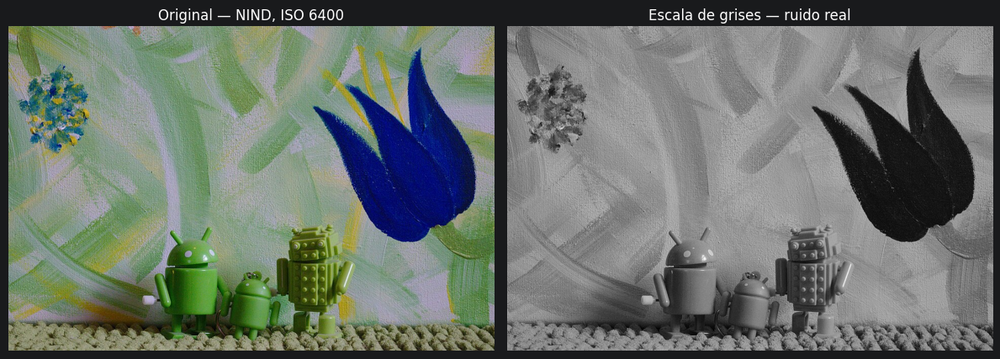

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
ejes[0].imshow(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB))
ejes[0].set_title('Original — NIND, ISO 6400')
ejes[1].imshow(ruido_real, cmap='gray', vmin=0, vmax=255)
ejes[1].set_title('Escala de grises — ruido real')
for eje in ejes:
    eje.axis('off')
fig.tight_layout()
plt.show()

## Ejercicio 1 · Banco reproducible de denoising

Se evalúan solamente las dos imágenes limpias (01 y 02). La fotografía 03 se reserva para inspección visual. Hay **9 configuraciones × 6 condiciones = 54 combinaciones por imagen**, no 60: el enunciado menciona diez filtros pero enumera nueve. El diccionario `filtros` permite añadir una configuración cuando se acuerde.

No se ha aportado el código literal de ruido del enunciado: aquí se explicita una implementación reproducible. Sal y pimienta usa una máscara uniforme con probabilidad total p (p/2 para 0 y p/2 para 255); el porcentaje es esperado, no un recuento exacto de píxeles alterados. El ruido gaussiano es aditivo, de media cero y sigma expresada en niveles de gris; se redondea y satura a [0,255]. Una semilla fija y un orden fijo generan una única muestra por condición, compartida por los nueve filtros.

In [4]:
def cargar_gris(ruta):
    imagen = cv2.imdecode(np.fromfile(ruta, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if imagen is None:
        raise ValueError(f'No se puede leer {ruta}')
    if imagen.ndim == 3:
        conversion = cv2.COLOR_BGRA2GRAY if imagen.shape[2] == 4 else cv2.COLOR_BGR2GRAY
        imagen = cv2.cvtColor(imagen, conversion)
    if imagen.dtype != np.uint8 or imagen.ndim != 2:
        raise ValueError(f'Se requiere uint8 de un canal: {ruta}')
    return imagen

nombres_limpias = ['01_textura_ladrillos.png', '02_bordes_monedas.png']
for nombre in nombres_limpias:
    if not (data_dir / nombre).is_file():
        raise FileNotFoundError(f'Falta la referencia limpia {nombre}')
limpias = {nombre: cargar_gris(data_dir / nombre) for nombre in nombres_limpias}
# Inventario: la etiqueta evita confundir la fotografía ISO6400 con referencia.
inventario = []
for ruta in sorted(data_dir.iterdir()):
    if ruta.suffix.lower() in {'.png', '.jpg', '.jpeg'}:
        im = cargar_gris(ruta)
        inventario.append({'imagen': ruta.name, 'alto': im.shape[0], 'ancho': im.shape[1],
                           'dtype': str(im.dtype), 'uso': 'referencia limpia' if ruta.name in limpias else 'solo visual'})
display(pd.DataFrame(inventario))


def ruido_sal_pimienta(imagen, proporcion, rng):
    mascara = rng.random(imagen.shape)
    resultado = imagen.copy()
    resultado[mascara < proporcion / 2] = 0
    resultado[mascara >= 1 - proporcion / 2] = 255
    return resultado


def ruido_gaussiano(imagen, sigma, rng):
    valores = imagen.astype(np.float64) + rng.normal(0, sigma, imagen.shape)
    return np.clip(np.rint(valores), 0, 255).astype(np.uint8)


condiciones = [('sal_pimienta', p) for p in (5, 10, 30)] + [('gaussiano', s) for s in (10, 20, 40)]
rng = np.random.default_rng(20260101)
ruidosas = {}
for nombre, limpia in limpias.items():
    for tipo, nivel in condiciones:
        ruidosa = (ruido_sal_pimienta(limpia, nivel / 100, rng) if tipo == 'sal_pimienta'
                   else ruido_gaussiano(limpia, nivel, rng))
        ruidosa.setflags(write=False)
        ruidosas[nombre, tipo, nivel] = ruidosa
print(f'{len(ruidosas)} muestras ruidosas generadas una única vez.')

,imagen,alto,ancho,dtype,uso
0,01_textura_ladrillos.png,512,512,uint8,referencia limpia
1,02_bordes_monedas.png,303,384,uint8,referencia limpia
2,03_ruido_real.png,641,960,uint8,solo visual
3,960px-NIND_droid_ISO6400.jpg,641,960,uint8,solo visual


12 muestras ruidosas generadas una única vez.


### Filtros y protocolo de medida

La **mediana híbrida 5×5** calcula la mediana de los 9 píxeles de la cruz (+), la de los 9 de las diagonales (×) y finalmente la mediana de estos dos valores y el píxel central. La **mediana truncada 5×5** ordena los 25 valores, elimina los 5 menores y los 5 mayores y promedia los 15 restantes (media alfa-recortada, una interpretación de la variante truncada). No se sustituye ninguna por `medianBlur`. Ambas se implementan con ventanas NumPy y mantienen uint8. Se usa borde replicado en todos los filtros, también en los de OpenCV.

Gaussianos: kernel automático `(0,0)` y sigma 1 o 2. Bilateral A: d=5, sigmaColor=25, sigmaSpace=5; B: d=9, sigmaColor=75, sigmaSpace=9. Los parámetros quedan registrados en el CSV.

Tiempo: un calentamiento y tres repeticiones por filtro; se registra la mediana de los tiempos con `perf_counter`, exclusivamente del filtrado (incluye sus conversiones internas). Lectura, ruido, métricas y gráficas quedan fuera del intervalo. OpenCV usa un hilo. Los tiempos dependen del equipo y su carga; no se espera igualdad exacta entre ejecuciones. PSNR y SSIM se calculan con data_range=255. SSIM usa ventana 7×7, pesos uniformes y covarianza muestral.

In [5]:
def ventanas_5(imagen):
    extendida = np.pad(imagen, 2, mode='edge')
    return sliding_window_view(extendida, (5, 5))


def mediana_hibrida(imagen):
    ventanas = ventanas_5(imagen)
    indices = np.arange(5)
    cruz = np.concatenate([ventanas[..., 2, :], ventanas[..., [0, 1, 3, 4], 2]], axis=-1)
    diagonales = np.concatenate([ventanas[..., indices, indices],
                                 ventanas[..., [0, 1, 3, 4], [4, 3, 1, 0]]], axis=-1)
    candidatos = np.stack([np.median(cruz, axis=-1), np.median(diagonales, axis=-1), imagen], axis=-1)
    return np.median(candidatos, axis=-1).astype(np.uint8)


def mediana_truncada(imagen):
    ventanas = ventanas_5(imagen)
    ordenados = np.sort(ventanas.reshape(*imagen.shape, 25), axis=-1)
    return np.rint(ordenados[..., 5:-5].mean(axis=-1)).astype(np.uint8)


# Registro ampliable: cada entrada contiene función y parámetros serializables.
borde = cv2.BORDER_REPLICATE
filtros = {
    'media_3': (lambda im: cv2.blur(im, (3, 3), borderType=borde), {'ksize': [3, 3]}),
    'gaussiano_1': (lambda im: cv2.GaussianBlur(im, (0, 0), 1.0, borderType=borde), {'ksize': [0, 0], 'sigma': 1.0}),
    'gaussiano_2': (lambda im: cv2.GaussianBlur(im, (0, 0), 2.0, borderType=borde), {'ksize': [0, 0], 'sigma': 2.0}),
    'mediana_3': (lambda im: cv2.medianBlur(im, 3), {'ksize': 3}),
    'mediana_5': (lambda im: cv2.medianBlur(im, 5), {'ksize': 5}),
    'mediana_hibrida': (mediana_hibrida, {'ksize': 5, 'definicion': 'mediana_cruz_diagonales_centro'}),
    'mediana_truncada': (mediana_truncada, {'ksize': 5, 'recorte_por_extremo': 5, 'agregacion': 'media'}),
    'bilateral_A': (lambda im: cv2.bilateralFilter(im, 5, 25, 5, borderType=borde), {'d': 5, 'sigmaColor': 25, 'sigmaSpace': 5}),
    'bilateral_B': (lambda im: cv2.bilateralFilter(im, 9, 75, 9, borderType=borde), {'d': 9, 'sigmaColor': 75, 'sigmaSpace': 9}),
}


def metricas(limpia, estimada):
    return (peak_signal_noise_ratio(limpia, estimada, data_range=255),
            structural_similarity(limpia, estimada, data_range=255, win_size=7,
                                  gaussian_weights=False, use_sample_covariance=True))


def medir_filtrado(funcion, imagen, repeticiones=3):
    funcion(imagen)  # Calentamiento fuera de la medida.
    tiempos = []
    for _ in range(repeticiones):
        inicio = perf_counter()
        resultado = funcion(imagen)
        tiempos.append((perf_counter() - inicio) * 1000)
    return resultado, float(np.median(tiempos))


# Comprobaciones pequeñas de las variantes manuales.
constante = np.full((7, 7), 80, dtype=np.uint8)
impulso = constante.copy()
impulso[3, 3] = 255
for funcion in (mediana_hibrida, mediana_truncada):
    assert np.array_equal(funcion(constante), constante)
    assert funcion(impulso)[3, 3] == 80
    assert funcion(impulso).shape == impulso.shape

### Evaluación y exportación

Cada muestra ruidosa se reutiliza sin cambios. Se conserva también su PSNR/SSIM antes de filtrar como línea base en un archivo independiente. La tabla principal tiene exactamente las ocho columnas solicitadas; `nivel` significa porcentaje total para sal y pimienta y sigma para gaussiano. La comprobación final compara el conjunto completo de claves imagen/ruido/nivel/filtro, detectando tanto ausencias como duplicados.

In [6]:
filas, bases, filtradas = [], [], {}
for (nombre, tipo, nivel), ruidosa in ruidosas.items():
    limpia = limpias[nombre]
    psnr_base, ssim_base = metricas(limpia, ruidosa)
    bases.append({'imagen': nombre, 'tipo_ruido': tipo, 'nivel': nivel, 'psnr': psnr_base, 'ssim': ssim_base})
    for etiqueta, (funcion, parametros) in filtros.items():
        resultado, tiempo_ms = medir_filtrado(funcion, ruidosa)
        assert resultado.dtype == np.uint8 and resultado.shape == limpia.shape
        psnr, ssim = metricas(limpia, resultado)
        filtradas[nombre, tipo, nivel, etiqueta] = resultado
        filas.append({'imagen': nombre, 'tipo_ruido': tipo, 'nivel': nivel, 'filtro': etiqueta,
                      'parametros': json.dumps({**parametros, 'borde': 'replicate'}, sort_keys=True),
                      'psnr': psnr, 'ssim': ssim, 'tiempo_ms': tiempo_ms})
    print(f'Evaluada: {nombre}, {tipo}, nivel={nivel}')

columnas = ['imagen', 'tipo_ruido', 'nivel', 'filtro', 'parametros', 'psnr', 'ssim', 'tiempo_ms']
resultados = pd.DataFrame(filas, columns=columnas)
linea_base = pd.DataFrame(bases)
claves = ['imagen', 'tipo_ruido', 'nivel', 'filtro']
esperadas = {(nombre, tipo, nivel, filtro) for nombre in limpias
             for tipo, nivel in condiciones for filtro in filtros}
assert set(resultados[claves].itertuples(index=False, name=None)) == esperadas
assert not resultados.duplicated(claves).any()
assert len(resultados) == len(limpias) * len(condiciones) * len(filtros)
assert np.isfinite(resultados[['psnr', 'ssim', 'tiempo_ms']].to_numpy()).all()
assert resultados['tiempo_ms'].gt(0).all()
assert resultados['ssim'].between(-1, 1).all()
resultados.to_csv(outputs_dir / 'resultados_denoising.csv', index=False)
linea_base.to_csv(outputs_dir / 'linea_base_ruidosa.csv', index=False)
print(f'Verificadas {len(resultados)} filas: {len(limpias)} imágenes × {len(condiciones)} condiciones × {len(filtros)} filtros.')

Evaluada: 01_textura_ladrillos.png, sal_pimienta, nivel=5
Evaluada: 01_textura_ladrillos.png, sal_pimienta, nivel=10
Evaluada: 01_textura_ladrillos.png, sal_pimienta, nivel=30
Evaluada: 01_textura_ladrillos.png, gaussiano, nivel=10
Evaluada: 01_textura_ladrillos.png, gaussiano, nivel=20
Evaluada: 01_textura_ladrillos.png, gaussiano, nivel=40
Evaluada: 02_bordes_monedas.png, sal_pimienta, nivel=5
Evaluada: 02_bordes_monedas.png, sal_pimienta, nivel=10
Evaluada: 02_bordes_monedas.png, sal_pimienta, nivel=30
Evaluada: 02_bordes_monedas.png, gaussiano, nivel=10
Evaluada: 02_bordes_monedas.png, gaussiano, nivel=20
Evaluada: 02_bordes_monedas.png, gaussiano, nivel=40
Verificadas 108 filas: 2 imágenes × 6 condiciones × 9 filtros.


### Tablas y figuras comparativas

Las tablas y los mapas de calor se presentan **por imagen**, para no ocultar diferencias entre textura y bordes. Las comparaciones visuales incluyen las nueve salidas, la referencia y la muestra ruidosa con escala fija 0–255. El gráfico temporal usa escala logarítmica. Se guarda cada figura antes de mostrarla y se comprueba la existencia de los archivos.

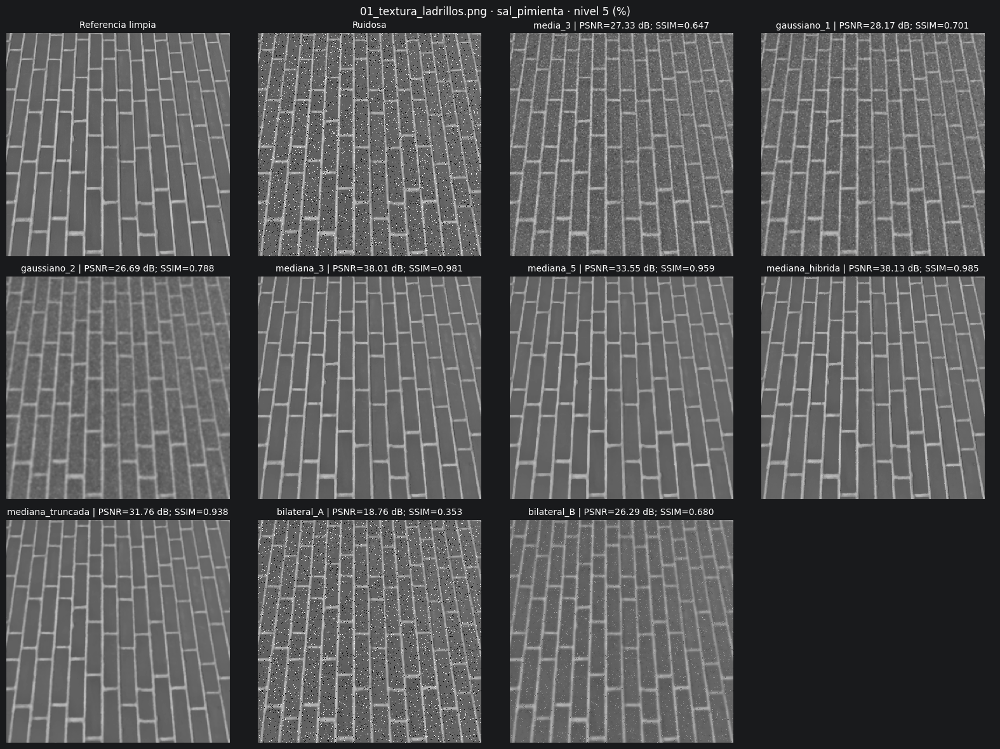

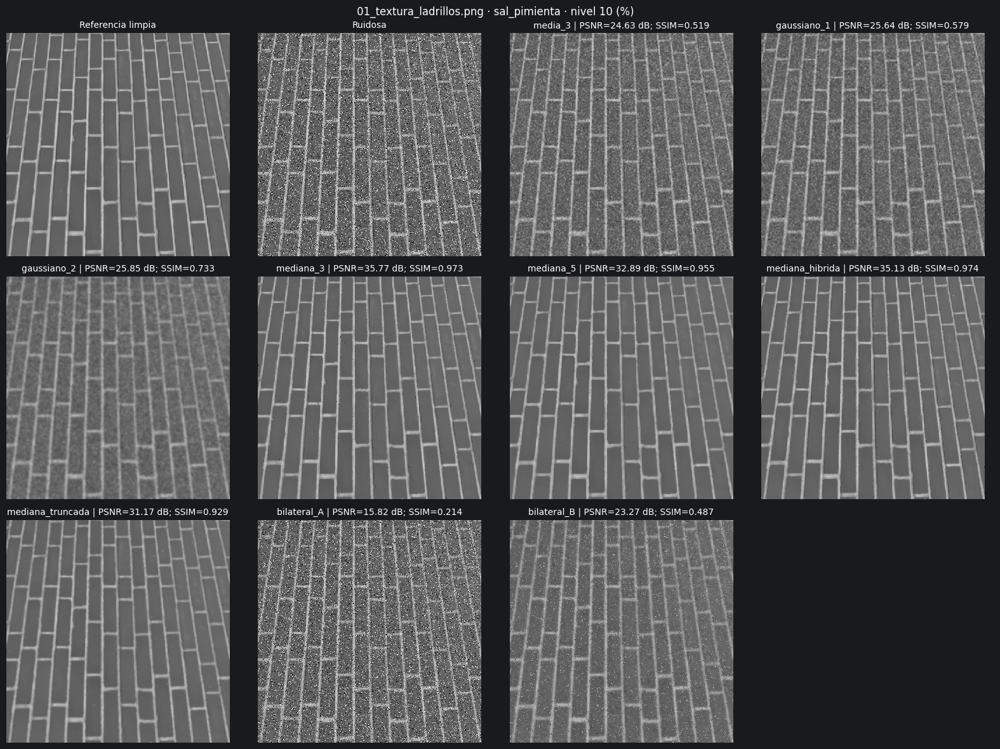

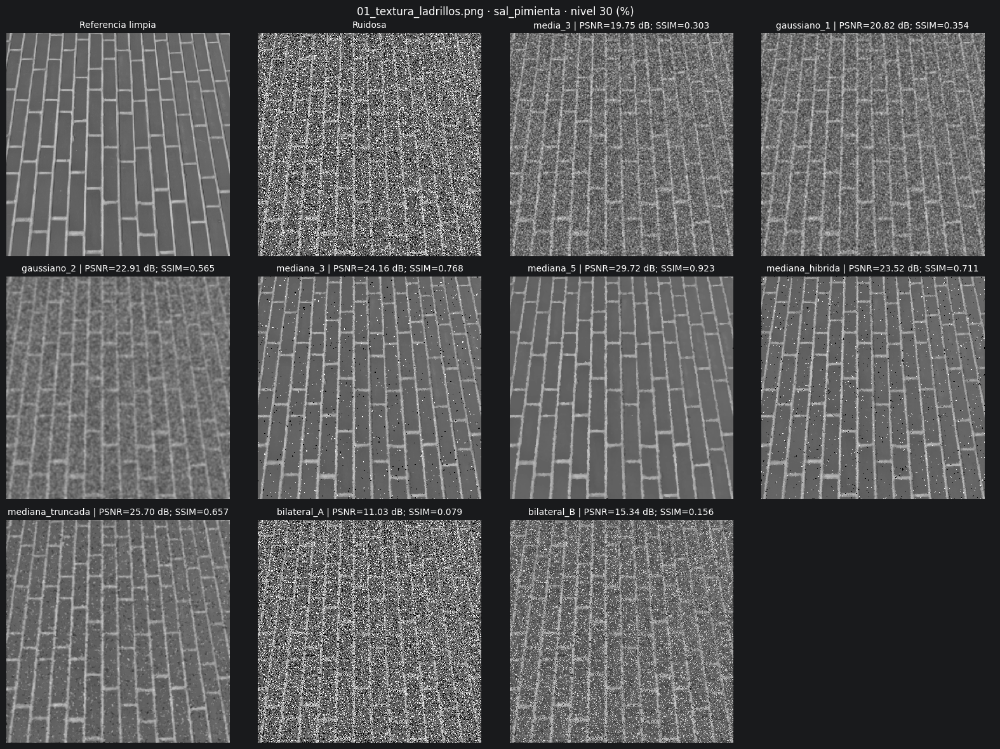

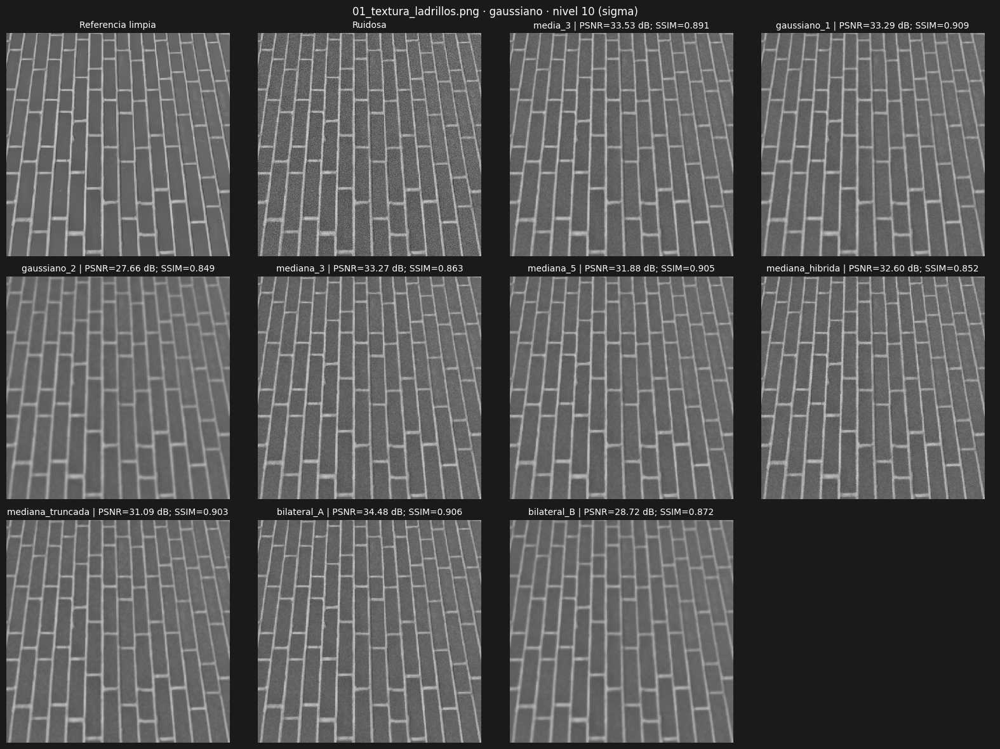

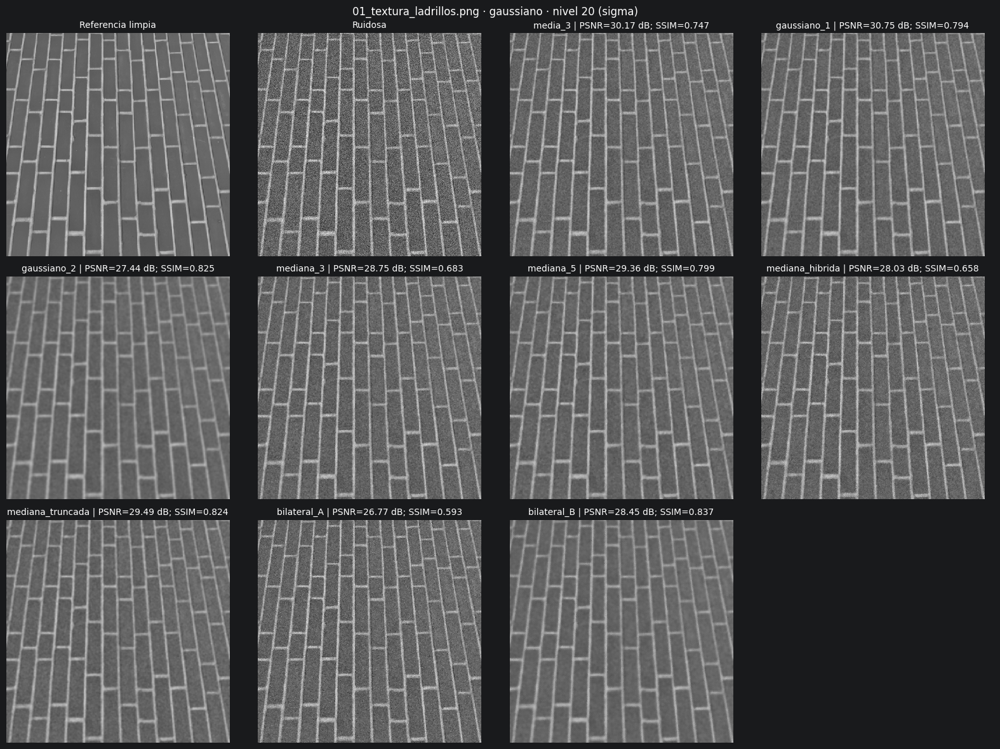

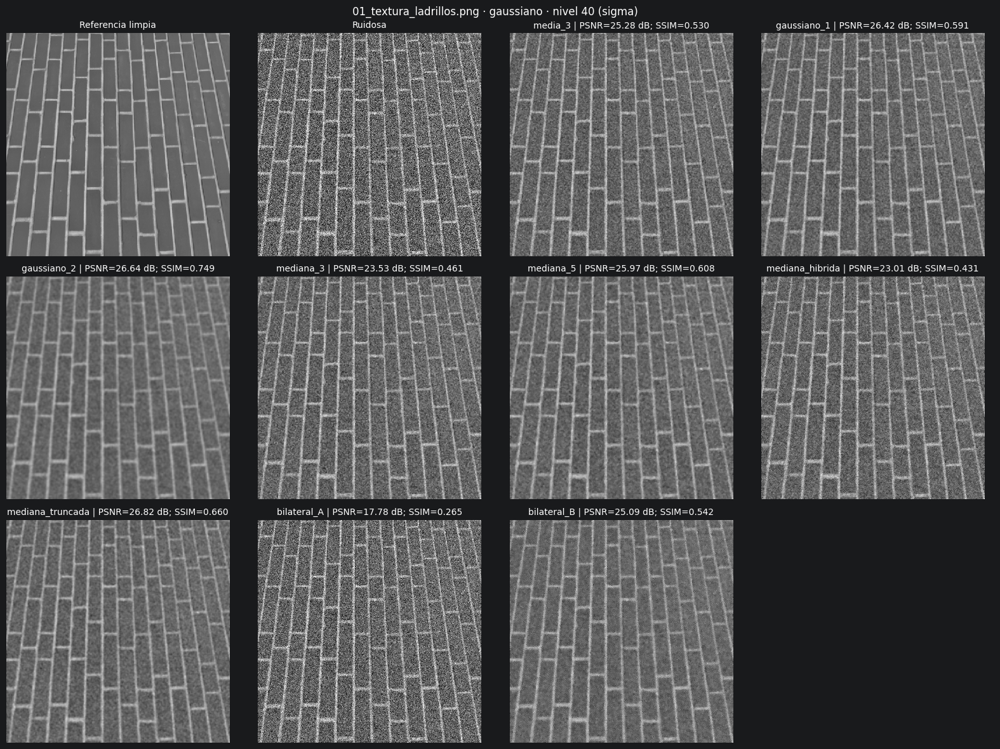

filtro              media_3  gaussiano_1  gaussiano_2  mediana_3  mediana_5  \
tipo_ruido   nivel                                                            
gaussiano    10      33.528       33.293       27.658     33.266     31.884   
             20      30.168       30.753       27.438     28.754     29.362   
             40      25.280       26.421       26.636     23.533     25.974   
sal_pimienta 5       27.326       28.169       26.695     38.009     33.547   
             10      24.630       25.637       25.848     35.769     32.893   
             30      19.748       20.819       22.910     24.161     29.717   

filtro              mediana_hibrida  mediana_truncada  bilateral_A  \
tipo_ruido   nivel                                                   
gaussiano    10              32.604            31.086       34.481   
             20              28.028            29.495       26.769   
             40              23.014            26.818       17.779   
sal_pimienta 5               38.125            31.760       18.757   
             10              35.135            31.169       15.819   
             30              23.522            25.696       11.030   

filtro              bilateral_B  
tipo_ruido   nivel               
gaussiano    10          28.719  
             20          28.454  
             40          25.086  
sal_pimienta 5           26.292  
             10          23.269  
             30          15.337

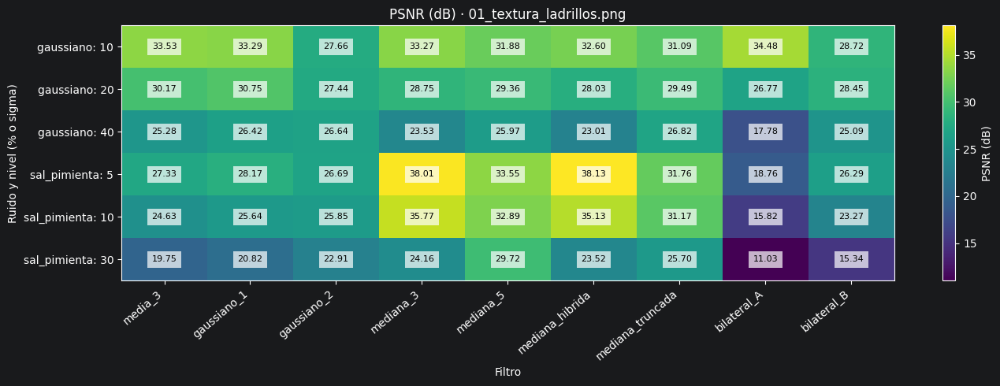

filtro              media_3  gaussiano_1  gaussiano_2  mediana_3  mediana_5  \
tipo_ruido   nivel                                                            
gaussiano    10       0.891        0.909        0.849      0.863      0.905   
             20       0.747        0.794        0.825      0.683      0.799   
             40       0.530        0.591        0.749      0.461      0.608   
sal_pimienta 5        0.647        0.701        0.788      0.981      0.959   
             10       0.519        0.579        0.733      0.973      0.955   
             30       0.303        0.354        0.565      0.768      0.923   

filtro              mediana_hibrida  mediana_truncada  bilateral_A  \
tipo_ruido   nivel                                                   
gaussiano    10               0.852             0.903        0.906   
             20               0.658             0.824        0.593   
             40               0.431             0.660        0.265   
sal_pimienta 5                0.985             0.938        0.353   
             10               0.974             0.929        0.214   
             30               0.711             0.657        0.079   

filtro              bilateral_B  
tipo_ruido   nivel               
gaussiano    10           0.872  
             20           0.837  
             40           0.542  
sal_pimienta 5            0.680  
             10           0.487  
             30           0.156

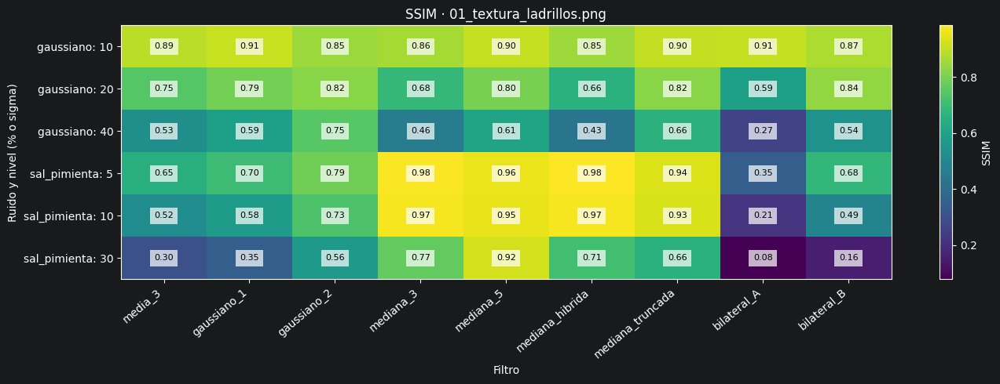

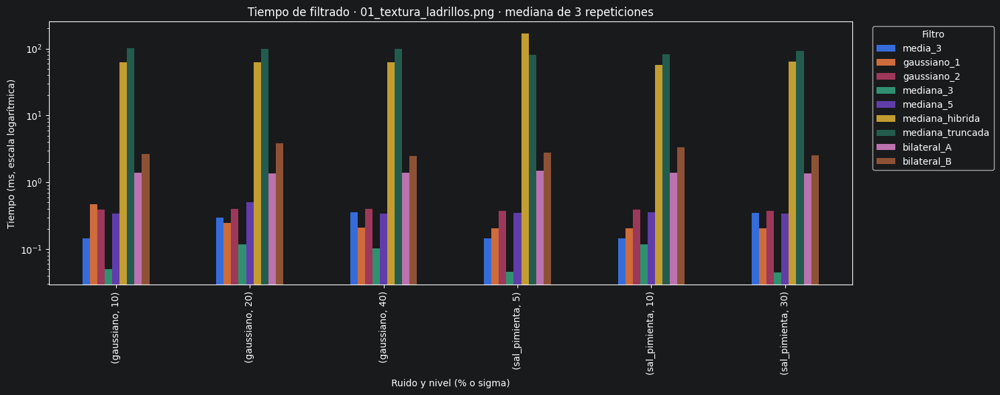

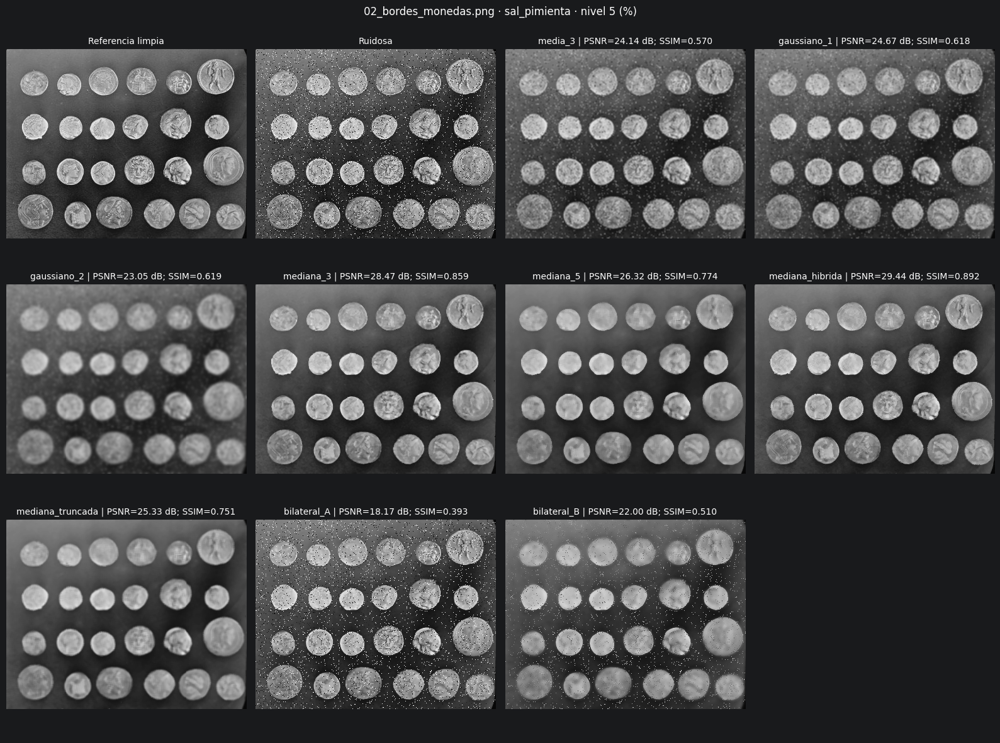

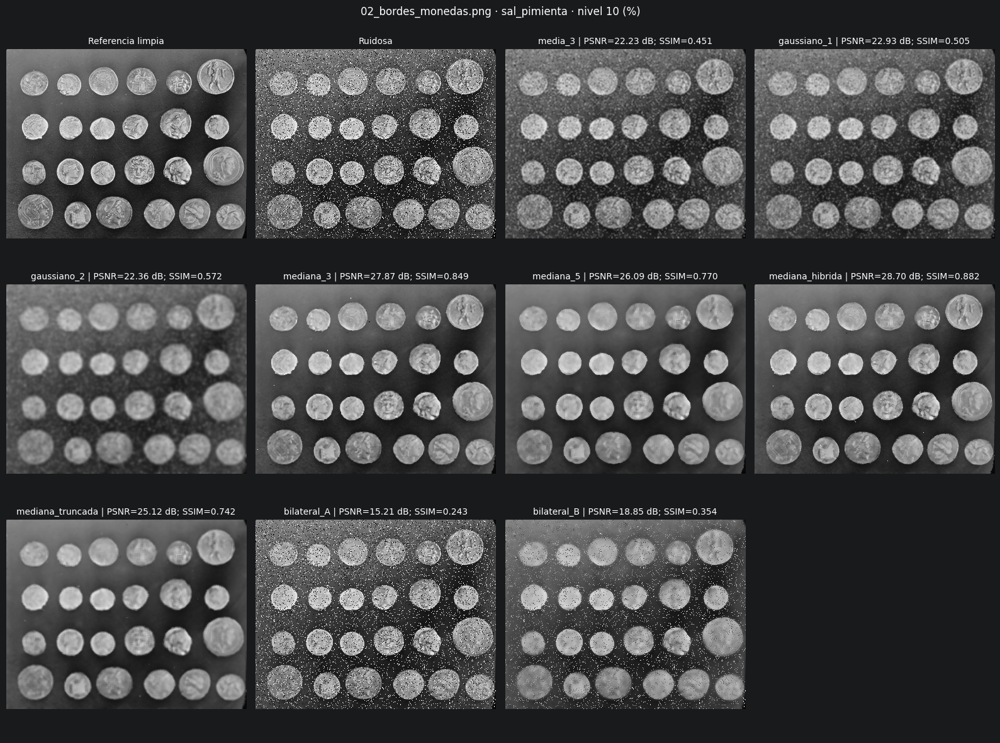

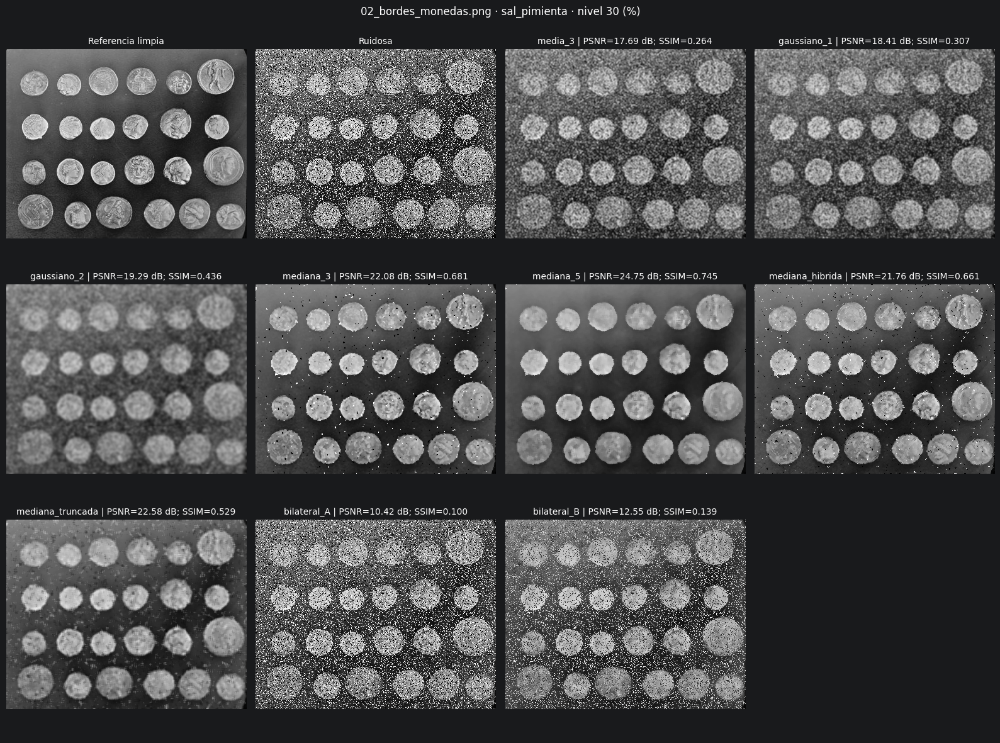

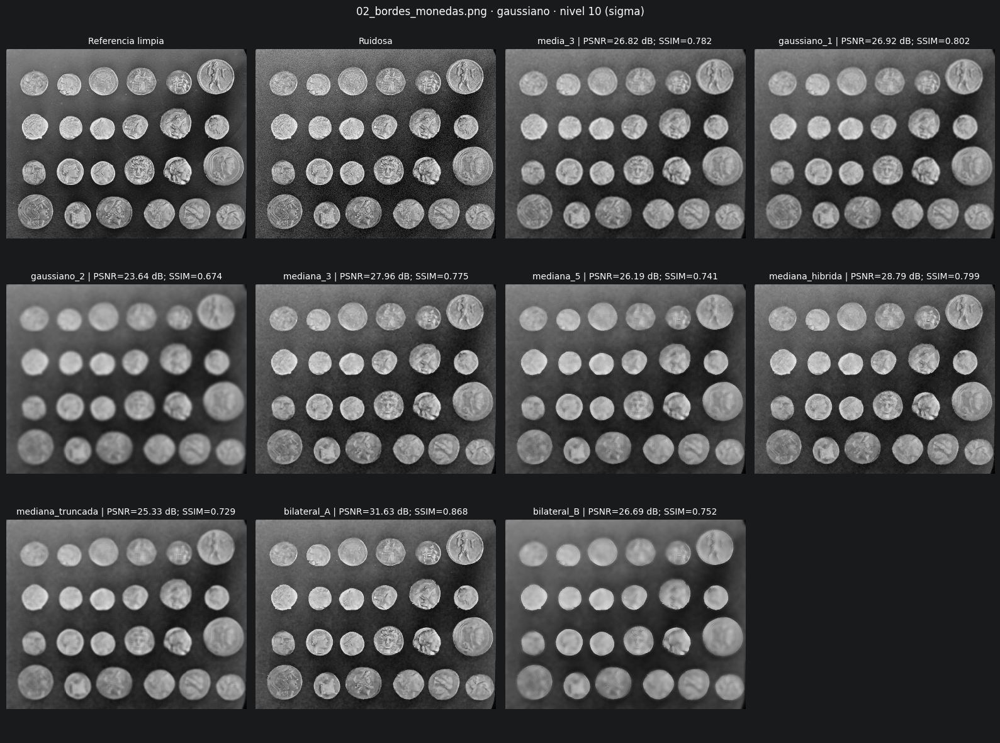

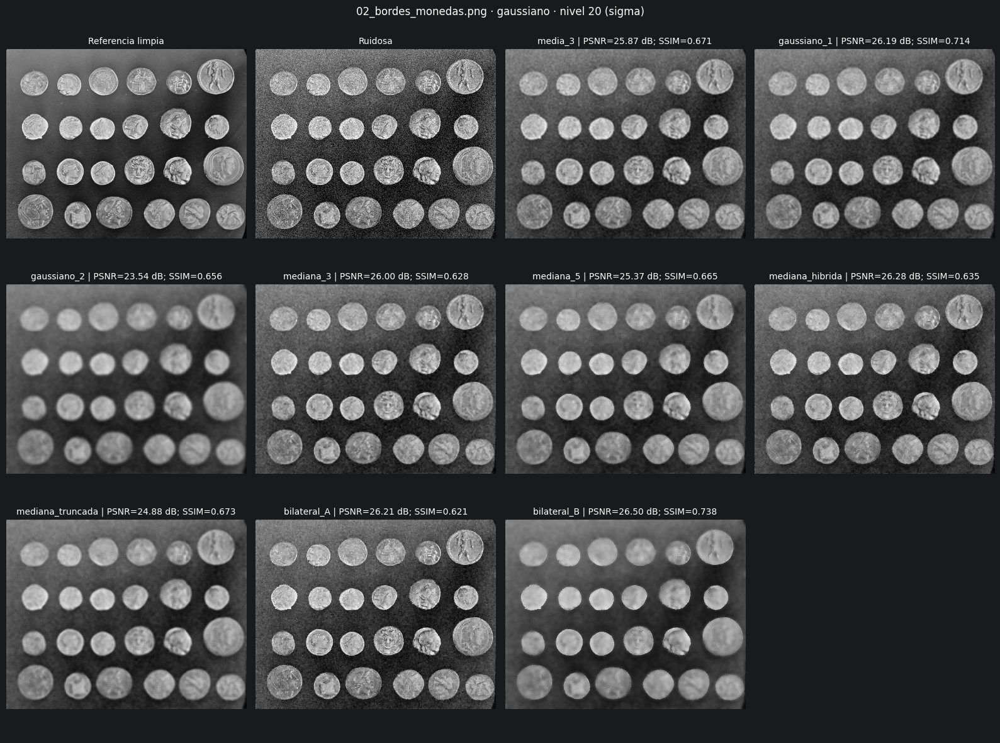

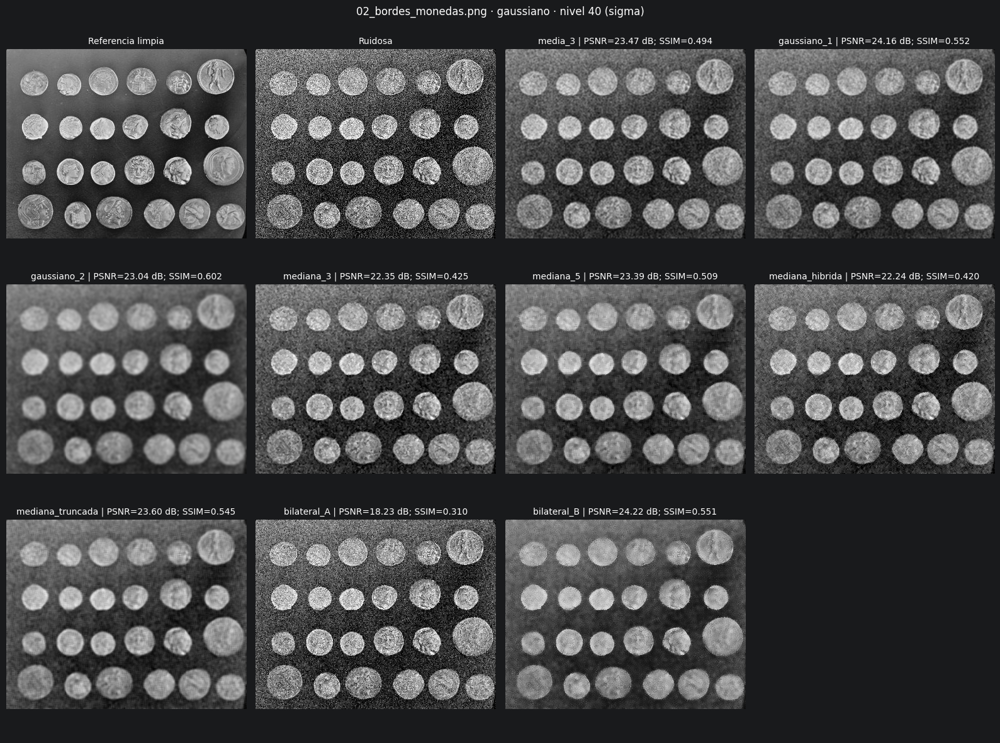

filtro              media_3  gaussiano_1  gaussiano_2  mediana_3  mediana_5  \
tipo_ruido   nivel                                                            
gaussiano    10      26.821       26.917       23.639     27.958     26.193   
             20      25.870       26.189       23.539     26.000     25.365   
             40      23.471       24.159       23.044     22.349     23.387   
sal_pimienta 5       24.142       24.667       23.052     28.472     26.321   
             10      22.232       22.930       22.364     27.871     26.090   
             30      17.689       18.410       19.286     22.083     24.751   

filtro              mediana_hibrida  mediana_truncada  bilateral_A  \
tipo_ruido   nivel                                                   
gaussiano    10              28.787            25.330       31.630   
             20              26.285            24.882       26.212   
             40              22.241            23.604       18.227   
sal_pimienta 5               29.443            25.329       18.169   
             10              28.704            25.117       15.210   
             30              21.760            22.575       10.424   

filtro              bilateral_B  
tipo_ruido   nivel               
gaussiano    10          26.689  
             20          26.495  
             40          24.218  
sal_pimienta 5           22.001  
             10          18.846  
             30          12.555

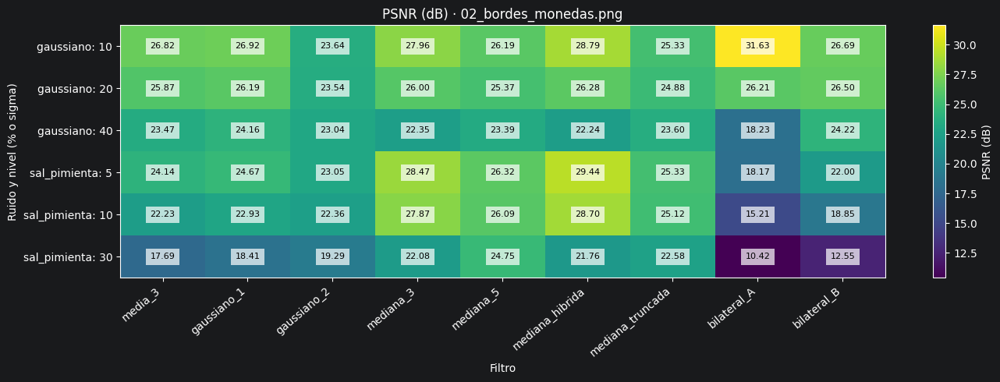

filtro              media_3  gaussiano_1  gaussiano_2  mediana_3  mediana_5  \
tipo_ruido   nivel                                                            
gaussiano    10       0.782        0.802        0.674      0.775      0.741   
             20       0.671        0.714        0.656      0.628      0.665   
             40       0.494        0.552        0.602      0.425      0.509   
sal_pimienta 5        0.570        0.618        0.619      0.859      0.774   
             10       0.451        0.505        0.572      0.849      0.770   
             30       0.264        0.307        0.436      0.681      0.745   

filtro              mediana_hibrida  mediana_truncada  bilateral_A  \
tipo_ruido   nivel                                                   
gaussiano    10               0.799             0.729        0.868   
             20               0.635             0.673        0.621   
             40               0.420             0.545        0.310   
sal_pimienta 5                0.892             0.751        0.393   
             10               0.882             0.742        0.243   
             30               0.661             0.529        0.100   

filtro              bilateral_B  
tipo_ruido   nivel               
gaussiano    10           0.752  
             20           0.738  
             40           0.551  
sal_pimienta 5            0.510  
             10           0.354  
             30           0.139

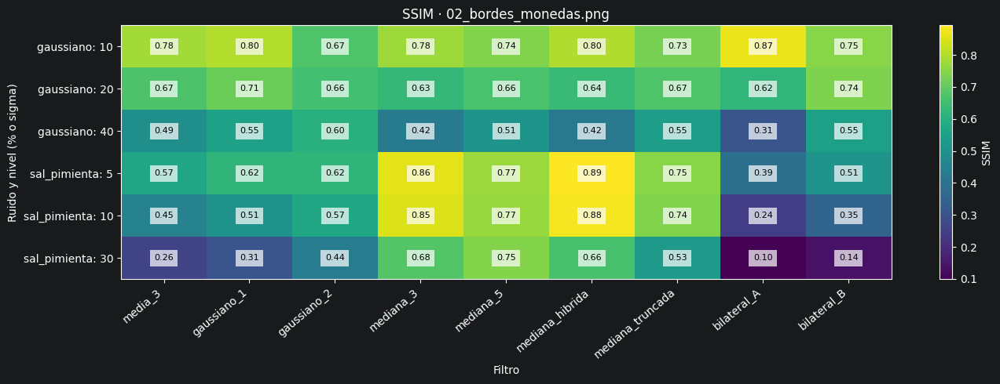

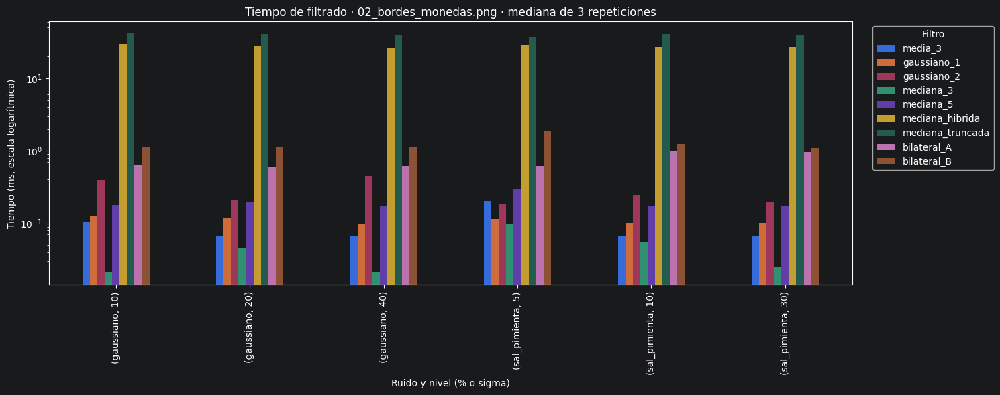

In [7]:
figuras_generadas = []


def guardar_figura(fig, nombre):
    ruta = outputs_dir / nombre
    fig.savefig(ruta, dpi=140, bbox_inches='tight')
    figuras_generadas.append(ruta)
    plt.show()
    plt.close(fig)


for nombre, limpia in limpias.items():
    for tipo, nivel in condiciones:
        fig, ejes = plt.subplots(3, 4, figsize=(16, 12))
        paneles = [('Referencia limpia', limpia), ('Ruidosa', ruidosas[nombre, tipo, nivel])]
        for filtro in filtros:
            fila = resultados.query('imagen == @nombre and tipo_ruido == @tipo and nivel == @nivel and filtro == @filtro').iloc[0]
            titulo = f'{filtro} | PSNR={fila.psnr:.2f} dB; SSIM={fila.ssim:.3f}'
            paneles.append((titulo, filtradas[nombre, tipo, nivel, filtro]))
        for eje in ejes.flat:
            eje.axis('off')
        for eje, (titulo, imagen) in zip(ejes.flat, paneles):
            eje.imshow(imagen, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
            eje.set_title(titulo, fontsize=10)
        unidad = '%' if tipo == 'sal_pimienta' else 'sigma'
        fig.suptitle(f'{nombre} · {tipo} · nivel {nivel} ({unidad})')
        fig.tight_layout()
        guardar_figura(fig, f'comparacion_{Path(nombre).stem}_{tipo}_{nivel}.png')

    datos = resultados[resultados.imagen == nombre]
    for metrica, unidad in [('psnr', 'PSNR (dB)'), ('ssim', 'SSIM')]:
        tabla = datos.pivot(index=['tipo_ruido', 'nivel'], columns='filtro', values=metrica).reindex(columns=list(filtros))
        display(tabla.round(3))
        tabla.to_csv(outputs_dir / f'resumen_{metrica}_{Path(nombre).stem}.csv')
        fig, eje = plt.subplots(figsize=(14, 5))
        mapa = eje.imshow(tabla.to_numpy(), aspect='auto', cmap='viridis')
        eje.set_xticks(range(len(tabla.columns)), tabla.columns, rotation=40, ha='right')
        eje.set_yticks(range(len(tabla)), [f'{tipo}: {nivel}' for tipo, nivel in tabla.index])
        eje.set_xlabel('Filtro')
        eje.set_ylabel('Ruido y nivel (% o sigma)')
        eje.set_title(f'{unidad} · {nombre}')
        for i in range(len(tabla)):
            for j in range(len(tabla.columns)):
                eje.text(j, i, f'{tabla.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8,
                         color='black', bbox={'facecolor': 'white', 'alpha': 0.7, 'edgecolor': 'none'})
        fig.colorbar(mapa, ax=eje, label=unidad)
        fig.tight_layout()
        guardar_figura(fig, f'calor_{metrica}_{Path(nombre).stem}.png')

    tiempos = datos.pivot(index=['tipo_ruido', 'nivel'], columns='filtro', values='tiempo_ms').reindex(columns=list(filtros))
    eje = tiempos.plot.bar(figsize=(15, 6), logy=True)
    eje.set_title(f'Tiempo de filtrado · {nombre} · mediana de 3 repeticiones')
    eje.set_xlabel('Ruido y nivel (% o sigma)')
    eje.set_ylabel('Tiempo (ms, escala logarítmica)')
    eje.legend(title='Filtro', bbox_to_anchor=(1.02, 1), loc='upper left')
    eje.figure.tight_layout()
    guardar_figura(eje.figure, f'tiempos_{Path(nombre).stem}.png')

## Análisis pendiente de revisión personal

Las tablas siguientes ofrecen cifras sin atribuirles una interpretación visual ni redactar conclusiones finales.

1. **Ganadores:** máximo de PSNR y máximo de SSIM por imagen, ruido y nivel; se mantienen todos los empates.
2. **Mediana frente a media en ruido impulsivo:** diferencias mediana−media para 3×3 y 5×5, ordenadas por porcentaje. La comparación 3×3 mantiene el tamaño de ventana.
3. **Mediana en ruido gaussiano:** métricas absolutas y diferencias respecto de la entrada ruidosa y del gaussiano sigma=1.
4. **Bilateral frente a gaussiano:** cada bilateral frente a ambos gaussianos, con cociente de tiempo y diferencia de SSIM. Cociente >1 significa mayor coste; delta SSIM >0, mayor SSIM.
5. **Elección visual:** se genera una plantilla para anotar el filtro preferido y el motivo tras revisar las láminas. Un desacuerdo entre los ganadores PSNR y SSIM no prueba un desacuerdo con la percepción visual. No se rellena esa valoración automáticamente.

In [8]:
grupos = ['imagen', 'tipo_ruido', 'nivel']


def exportar_tabla(tabla, nombre):
    display(tabla.round(4))
    tabla.to_csv(outputs_dir / nombre, index=False)


ganadores_lista = []
for metrica in ['psnr', 'ssim']:
    maximos = resultados.groupby(grupos)[metrica].transform('max')
    mejores = resultados.loc[resultados[metrica].eq(maximos), grupos + ['filtro', metrica]].copy()
    mejores = mejores.rename(columns={metrica: 'valor'})
    mejores['metrica'] = metrica
    ganadores_lista.append(mejores)
ganadores = pd.concat(ganadores_lista, ignore_index=True)
exportar_tabla(ganadores, 'analisis_1_ganadores.csv')

media = resultados[resultados.filtro == 'media_3'][grupos + ['psnr', 'ssim']]
medianas = resultados[resultados.filtro.isin(['mediana_3', 'mediana_5'])].copy()
ventaja = medianas[medianas.tipo_ruido == 'sal_pimienta'].merge(media, on=grupos, suffixes=('', '_media'))
ventaja['delta_psnr_mediana_media'] = ventaja.psnr - ventaja.psnr_media
ventaja['delta_ssim_mediana_media'] = ventaja.ssim - ventaja.ssim_media
exportar_tabla(ventaja.sort_values(['imagen', 'filtro', 'nivel']), 'analisis_2_mediana_media.csv')

gauss = resultados[resultados.filtro == 'gaussiano_1'][grupos + ['psnr', 'ssim']]
med_gauss = medianas[medianas.tipo_ruido == 'gaussiano'].merge(linea_base, on=grupos, suffixes=('', '_ruidosa'))
med_gauss = med_gauss.merge(gauss.rename(columns={'psnr': 'psnr_gauss1', 'ssim': 'ssim_gauss1'}), on=grupos)
for metrica in ['psnr', 'ssim']:
    med_gauss[f'delta_{metrica}_vs_ruidosa'] = med_gauss[metrica] - med_gauss[f'{metrica}_ruidosa']
    med_gauss[f'delta_{metrica}_vs_gauss1'] = med_gauss[metrica] - med_gauss[f'{metrica}_gauss1']
exportar_tabla(med_gauss, 'analisis_3_mediana_gaussiano.csv')

bilaterales = resultados[resultados.filtro.str.startswith('bilateral')]
gaussianos = resultados[resultados.filtro.str.startswith('gaussiano')]
coste = bilaterales.merge(gaussianos, on=grupos, suffixes=('_bilateral', '_gaussiano'))
coste['cociente_tiempo_bilateral_gaussiano'] = coste.tiempo_ms_bilateral / coste.tiempo_ms_gaussiano
coste['delta_ssim_bilateral_gaussiano'] = coste.ssim_bilateral - coste.ssim_gaussiano
exportar_tabla(coste[grupos + ['filtro_bilateral', 'filtro_gaussiano', 'tiempo_ms_bilateral',
                             'tiempo_ms_gaussiano', 'cociente_tiempo_bilateral_gaussiano',
                             'ssim_bilateral', 'ssim_gaussiano', 'delta_ssim_bilateral_gaussiano']],
               'analisis_4_bilateral_gaussiano.csv')

revision_visual = ganadores.pivot_table(index=grupos, columns='metrica', values='filtro',
                                       aggfunc=lambda valores: ' / '.join(valores)).reset_index()
revision_visual['eleccion_visual'] = ''
revision_visual['motivo_y_region_observada'] = ''
# No sobrescribir anotaciones personales al volver a ejecutar el notebook.
ruta_revision = outputs_dir / 'analisis_5_revision_visual.csv'
if not ruta_revision.exists():
    revision_visual.to_csv(ruta_revision, index=False)
display(pd.read_csv(ruta_revision).fillna(''))

# Verificar el CSV realmente escrito y todos los gráficos esperados.
leido = pd.read_csv(outputs_dir / 'resultados_denoising.csv')
assert list(leido.columns) == columnas
assert len(leido) == len(esperadas)
assert not leido.duplicated(claves).any()
assert set(leido[claves].itertuples(index=False, name=None)) == esperadas
assert len(figuras_generadas) == len(limpias) * (len(condiciones) + 3)
for ruta in figuras_generadas:
    assert ruta.is_file() and ruta.stat().st_size > 0
    figura_leida = plt.imread(ruta)
    assert figura_leida.ndim == 3 and figura_leida.size > 0
print(f'Validación final: {len(leido)} filas y {len(figuras_generadas)} figuras PNG legibles.')

,imagen,tipo_ruido,nivel,filtro,valor,metrica
0,01_textura_ladrillos.png,sal_pimienta,5,mediana_hibrida,38.1250,psnr
1,01_textura_ladrillos.png,sal_pimienta,10,mediana_3,35.7691,psnr
2,01_textura_ladrillos.png,sal_pimienta,30,mediana_5,29.7169,psnr
3,01_textura_ladrillos.png,gaussiano,10,bilateral_A,34.4814,psnr
4,01_textura_ladrillos.png,gaussiano,20,gaussiano_1,30.7530,psnr
5,01_textura_ladrillos.png,gaussiano,40,mediana_truncada,26.8180,psnr
6,02_bordes_monedas.png,sal_pimienta,5,mediana_hibrida,29.4429,psnr
7,02_bordes_monedas.png,sal_pimienta,10,mediana_hibrida,28.7036,psnr
8,02_bordes_monedas.png,sal_pimienta,30,mediana_5,24.7513,psnr
9,02_bordes_monedas.png,gaussiano,10,bilateral_A,31.6299,psnr


,imagen,tipo_ruido,nivel,filtro,parametros,psnr,ssim,tiempo_ms,psnr_media,ssim_media,delta_psnr_mediana_media,delta_ssim_mediana_media
0,01_textura_ladrillos.png,sal_pimienta,5,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",38.0092,0.9808,0.0462,27.3260,0.6465,10.6831,0.3343
2,01_textura_ladrillos.png,sal_pimienta,10,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",35.7691,0.9734,0.1185,24.6299,0.5188,11.1392,0.4546
4,01_textura_ladrillos.png,sal_pimienta,30,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",24.1606,0.7680,0.0444,19.7476,0.3035,4.4130,0.4645
1,01_textura_ladrillos.png,sal_pimienta,5,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",33.5466,0.9590,0.3482,27.3260,0.6465,6.2206,0.3125
3,01_textura_ladrillos.png,sal_pimienta,10,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",32.8934,0.9547,0.3595,24.6299,0.5188,8.2635,0.4359
5,01_textura_ladrillos.png,sal_pimienta,30,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",29.7169,0.9231,0.3421,19.7476,0.3035,9.9693,0.6196
6,02_bordes_monedas.png,sal_pimienta,5,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",28.4719,0.8585,0.1001,24.1425,0.5700,4.3295,0.2885
8,02_bordes_monedas.png,sal_pimienta,10,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",27.8710,0.8494,0.0553,22.2316,0.4513,5.6394,0.3981
10,02_bordes_monedas.png,sal_pimienta,30,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",22.0828,0.6806,0.0247,17.6890,0.2636,4.3938,0.4170
7,02_bordes_monedas.png,sal_pimienta,5,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",26.3215,0.7739,0.2975,24.1425,0.5700,2.1790,0.2038


,imagen,tipo_ruido,nivel,filtro,parametros,psnr,ssim,tiempo_ms,psnr_ruidosa,ssim_ruidosa,psnr_gauss1,ssim_gauss1,delta_psnr_vs_ruidosa,delta_psnr_vs_gauss1,delta_ssim_vs_ruidosa,delta_ssim_vs_gauss1
0,01_textura_ladrillos.png,gaussiano,10,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",33.2665,0.8629,0.0503,28.1237,0.6174,33.2926,0.9092,5.1428,-0.0261,0.2455,-0.0463
1,01_textura_ladrillos.png,gaussiano,10,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",31.8836,0.9047,0.3409,28.1237,0.6174,33.2926,0.9092,3.7599,-1.4090,0.2873,-0.0045
2,01_textura_ladrillos.png,gaussiano,20,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",28.7542,0.6827,0.1173,22.1058,0.4012,30.7530,0.7943,6.6484,-1.9988,0.2815,-0.1116
3,01_textura_ladrillos.png,gaussiano,20,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",29.3616,0.7992,0.5017,22.1058,0.4012,30.7530,0.7943,7.2559,-1.3914,0.3980,0.0049
4,01_textura_ladrillos.png,gaussiano,40,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",23.5333,0.4605,0.1029,16.1488,0.2220,26.4208,0.5907,7.3845,-2.8875,0.2386,-0.1302
5,01_textura_ladrillos.png,gaussiano,40,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",25.9741,0.6080,0.3426,16.1488,0.2220,26.4208,0.5907,9.8253,-0.4467,0.3860,0.0172
6,02_bordes_monedas.png,gaussiano,10,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",27.9582,0.7753,0.0209,28.1336,0.6821,26.9173,0.8021,-0.1755,1.0408,0.0932,-0.0267
7,02_bordes_monedas.png,gaussiano,10,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",26.1931,0.7413,0.1784,28.1336,0.6821,26.9173,0.8021,-1.9405,-0.7242,0.0592,-0.0607
8,02_bordes_monedas.png,gaussiano,20,mediana_3,"{""borde"": ""replicate"", ""ksize"": 3}",26.0005,0.6285,0.0450,22.1740,0.4552,26.1895,0.7136,3.8265,-0.1890,0.1733,-0.0851
9,02_bordes_monedas.png,gaussiano,20,mediana_5,"{""borde"": ""replicate"", ""ksize"": 5}",25.3653,0.6647,0.1975,22.1740,0.4552,26.1895,0.7136,3.1913,-0.8242,0.2095,-0.0490


,imagen,tipo_ruido,nivel,filtro_bilateral,filtro_gaussiano,tiempo_ms_bilateral,tiempo_ms_gaussiano,cociente_tiempo_bilateral_gaussiano,ssim_bilateral,ssim_gaussiano,delta_ssim_bilateral_gaussiano
0,01_textura_ladrillos.png,sal_pimienta,5,bilateral_A,gaussiano_1,1.4825,0.2067,7.1722,0.3527,0.7014,-0.3487
1,01_textura_ladrillos.png,sal_pimienta,5,bilateral_A,gaussiano_2,1.4825,0.3734,3.9703,0.3527,0.7876,-0.4350
2,01_textura_ladrillos.png,sal_pimienta,5,bilateral_B,gaussiano_1,2.8038,0.2067,13.5646,0.6800,0.7014,-0.0213
3,01_textura_ladrillos.png,sal_pimienta,5,bilateral_B,gaussiano_2,2.8038,0.3734,7.5088,0.6800,0.7876,-0.1076
4,01_textura_ladrillos.png,sal_pimienta,10,bilateral_A,gaussiano_1,1.3830,0.2047,6.7562,0.2136,0.5789,-0.3653
5,01_textura_ladrillos.png,sal_pimienta,10,bilateral_A,gaussiano_2,1.3830,0.3883,3.5617,0.2136,0.7327,-0.5191
6,01_textura_ladrillos.png,sal_pimienta,10,bilateral_B,gaussiano_1,3.3051,0.2047,16.1461,0.4870,0.5789,-0.0919
7,01_textura_ladrillos.png,sal_pimienta,10,bilateral_B,gaussiano_2,3.3051,0.3883,8.5117,0.4870,0.7327,-0.2457
8,01_textura_ladrillos.png,sal_pimienta,30,bilateral_A,gaussiano_1,1.3592,0.2053,6.6206,0.0789,0.3538,-0.2748
9,01_textura_ladrillos.png,sal_pimienta,30,bilateral_A,gaussiano_2,1.3592,0.3770,3.6053,0.0789,0.5649,-0.4859


,imagen,tipo_ruido,nivel,psnr,ssim,eleccion_visual,motivo_y_region_observada
0,01_textura_ladrillos.png,gaussiano,10,bilateral_A,gaussiano_1,,
1,01_textura_ladrillos.png,gaussiano,20,gaussiano_1,bilateral_B,,
2,01_textura_ladrillos.png,gaussiano,40,mediana_truncada,gaussiano_2,,
3,01_textura_ladrillos.png,sal_pimienta,5,mediana_hibrida,mediana_hibrida,,
4,01_textura_ladrillos.png,sal_pimienta,10,mediana_3,mediana_hibrida,,
5,01_textura_ladrillos.png,sal_pimienta,30,mediana_5,mediana_5,,
6,02_bordes_monedas.png,gaussiano,10,bilateral_A,bilateral_A,,
7,02_bordes_monedas.png,gaussiano,20,bilateral_B,bilateral_B,,
8,02_bordes_monedas.png,gaussiano,40,bilateral_B,gaussiano_2,,
9,02_bordes_monedas.png,sal_pimienta,5,mediana_hibrida,mediana_hibrida,,


Validación final: 108 filas y 18 figuras PNG legibles.


### Ejecución

Desde la raíz del proyecto, instalar en el entorno seleccionado: `python -m pip install -r codigo/requirements.txt`. Abrir este notebook con ese intérprete, reiniciar el kernel y ejecutar todas las celdas en orden. No se instalan paquetes desde el notebook. Las métricas son reproducibles con estas versiones y semilla; los tiempos pueden variar. Los archivos de resultados y figuras se regeneran en `outputs/`; la plantilla de revisión visual se conserva para proteger las anotaciones. No se incluyen los ejercicios 2, 3 ni 4 ni el informe final.